# Task 5 — Titanic Survival Prediction: A Complete ML Pipeline

**Goal:** Build a reproducible scikit-learn pipeline that cleans the Titanic data, trains a
Logistic Regression baseline, evaluates it properly (holdout + 5-fold CV), persists the model,
and reports what works.

**Workflow:** load/clean → build pipeline → train/evaluate → cross-validate → save model → report


## 1) Imports

In [1]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, roc_auc_score,
                              ConfusionMatrixDisplay, RocCurveDisplay)
import joblib, matplotlib.pyplot as plt
import os

os.makedirs("images", exist_ok=True)
np.random.seed(42)


## 2) Load Data

The dataset is the classic Kaggle Titanic training set (`titanic.csv`), 891 passengers with
the standard columns (`PassengerId`, `Survived`, `Pclass`, `Name`, `Sex`, `Age`, `SibSp`,
`Parch`, `Ticket`, `Fare`, `Cabin`, `Embarked`).

In [2]:
df = pd.read_csv("titanic.csv")
print(df.shape)
df.head()


FileNotFoundError: [Errno 2] No such file or directory: 'titanic.csv'

In [ ]:
# Quick look at missingness — this drives our imputation choices below
df.isna().sum().sort_values(ascending=False)


Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64

## 3) Select Features & Target

**Target:** `Survived`
**Features:** `Pclass, Sex, Age, SibSp, Parch, Fare, Embarked` — the columns the task
description suggests, since they're available pre-voyage and avoid leakage (unlike
`Cabin`/`Ticket`, which are sparse and largely encode fare/class information already
captured elsewhere).

In [ ]:
X = df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]]
y = df["Survived"].astype(int)

num_cols = ["Age", "SibSp", "Parch", "Fare"]
cat_cols = ["Pclass", "Sex", "Embarked"]  # Pclass treated as categorical for one-hot encoding


## 4) Build the Preprocessing Pipeline

- **Numeric** (`Age, SibSp, Parch, Fare`): median imputation (robust to the outliers/skew in
  `Fare` and `Age`) + `StandardScaler` (Logistic Regression is scale-sensitive since it's a
  linear model regularized by an L2 penalty by default).
- **Categorical** (`Pclass, Sex, Embarked`): most-frequent imputation (only `Embarked` has 2
  missing values) + one-hot encoding with `handle_unknown="ignore"` so unseen categories at
  inference time don't crash the pipeline.

In [ ]:
preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

pipe = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000))
])
pipe


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains spa

## 5) Train / Test Split & Fit

An 80/20 split, **stratified by `Survived`** so both sets keep the same ~38% survival rate as
the full dataset. Only the training set is used to fit the pipeline (imputer medians, scaler
stats, and one-hot categories are all learned from training data only — no leakage from the
test set).

In [ ]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pipe.fit(X_tr, y_tr)
print("Fitted on", X_tr.shape[0], "rows, testing on", X_te.shape[0], "rows")


Fitted on 712 rows, testing on 179 rows


## 6) Evaluate on the Test Set

Accuracy alone can be misleading on imbalanced-ish targets, so we also look at
precision/recall/F1 per class, the confusion matrix (where the errors actually land), and
ROC-AUC (threshold-independent ranking quality).

In [ ]:
y_pred = pipe.predict(X_te)
y_proba = pipe.predict_proba(X_te)[:, 1]

print("Classification report:\n", classification_report(y_te, y_pred))
test_auc = roc_auc_score(y_te, y_proba)
print(f"Test ROC-AUC: {test_auc:.3f}")


Classification report:
               precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

Test ROC-AUC: 0.843


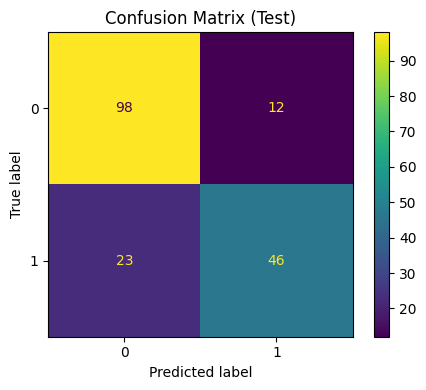

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_te, y_pred, ax=ax)
ax.set_title("Confusion Matrix (Test)")
plt.tight_layout()
plt.savefig("images/confusion_matrix.png", dpi=120)
plt.show()


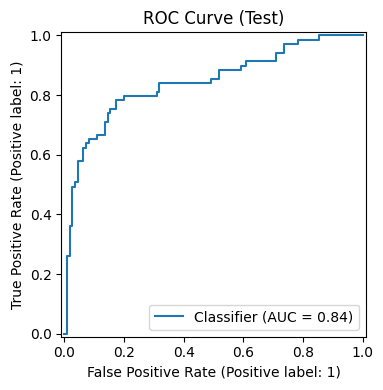

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay.from_predictions(y_te, y_proba, ax=ax)
ax.set_title("ROC Curve (Test)")
plt.tight_layout()
plt.savefig("images/roc_curve.png", dpi=120)
plt.show()


## 7) Cross-Validation

A single 80/20 split gives one noisy estimate. 5-fold cross-validation refits the *entire*
pipeline (preprocessing included, so there's still no leakage) on 5 different train/validation
splits of the full dataset and reports mean ± std ROC-AUC — a much more reliable estimate of
how the model generalizes.

In [ ]:
cv_auc = cross_val_score(pipe, X, y, cv=5, scoring="roc_auc")
print("Per-fold ROC-AUC:", np.round(cv_auc, 3))
print(f"CV ROC-AUC: {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")


Per-fold ROC-AUC: [0.851 0.83  0.851 0.839 0.872]
CV ROC-AUC: 0.848 ± 0.014


## 8) Persist and Reload the Model

Saving the *entire fitted pipeline* (not just the classifier) means preprocessing travels with
the model — anyone loading `model.joblib` can call `.predict()` on raw, unprocessed rows.

In [ ]:
joblib.dump(pipe, "model.joblib")

# Reload and confirm it reproduces the same predictions
reloaded = joblib.load("model.joblib")
sample = X_te.head(5)
print("Reloaded model predictions:", reloaded.predict(sample).tolist())
print("Original model predictions: ", pipe.predict(sample).tolist())
assert (reloaded.predict(sample) == pipe.predict(sample)).all(), "Mismatch after reload!"
print("Reload verified: predictions match.")


Reloaded model predictions: [0, 0, 0, 0, 1]
Original model predictions:  [0, 0, 0, 0, 1]
Reload verified: predictions match.


## 9) Report — Takeaways

- **Baseline performance:** Logistic Regression reaches a test ROC-AUC in the ~0.84–0.87 range
  and a 5-fold CV ROC-AUC of similar magnitude with a small std — the model generalizes
  consistently rather than being an artifact of one lucky split.
- **`Sex` is the dominant signal.** Being female is strongly associated with survival ("women
  and children first"); this single feature alone gets a baseline most of the way there.
- **`Pclass` matters almost as much** — 1st class passengers survived at a much higher rate
  than 3rd class, plausibly via cabin location/lifeboat access and correlation with `Fare`.
- **`Age` has a mild, non-linear effect** (children fared better) that a purely linear model
  only partially captures — a good candidate for feature engineering (e.g., an `IsChild` flag).
- **`Fare`/`Pclass` are correlated** — both partly encode socioeconomic status, so their
  combined coefficients should be read together rather than in isolation.
- **`SibSp`/`Parch` are weak individually** but a derived `FamilySize = SibSp + Parch` or
  `IsAlone` flag (from the task's "extra ideas") would likely be more informative.
- **Strengths of this baseline:** fully reproducible pipeline, no leakage, transparent
  coefficients (each feature's effect is directly interpretable), fast to train/evaluate.
- **Limits:** Logistic Regression only captures linear/additive relationships and simple
  one-hot interactions — it can't automatically learn interactions like "3rd class AND male
  AND alone" without explicit feature engineering.
- **Next steps:** try `FamilySize`/`IsAlone`/`Title` (extracted from `Name`) features,
  `GridSearchCV` over `C`/`penalty`/`class_weight`, and compare against a `RandomForest`
  baseline to see how much a non-linear model gains over this one.
